# 04. Empirical Parameter Ranges

Notebook 02 records the source review, and Notebook 03 checks the equations with hypothetical inputs. Here I bring together the numerical evidence that can already be used and show where the data still do not support a Study 3 parameter.

Observed values, literature estimates, and scenario calculations are labeled separately.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt

## Source-supported numerical anchors

The values below help set the scale of the model. Some are measured environmental conditions, while others are literature-derived parameter ranges or regulatory benchmarks. They do not all serve the same purpose.

In [2]:
parameter_rows = []

parameter_rows.append({"pollutant": "PM2.5",
                       "quantity": "Annual mean exposure, µg/m³",
                       "numerical evidence": "CDC modeled county estimates averaged over 2020 and population-weighted to Census regions",
                       "evidence type": "Model-derived exposure data",
                       "uncertainty or range": "County population coverage ranges from 93.76% to 99.83%. Model uncertainty and coverage affect regional estimates",
                       "current use": "2020 Census-region exposure baseline selected; emissions transfer coefficients remain uncalibrated",
                       "source": "https://data.cdc.gov/Environmental-Health-Toxicology/Daily-County-Level-PM2-5-Concentrations-2001-2022/53mz-4zqd"})

parameter_rows.append({"pollutant": "CO2",
                       "quantity": "Global annual mean, ppm dry-air mole fraction",
                       "numerical evidence": "425.62 ± 0.05 ppm (2025)",
                       "evidence type": "Observed global mean",
                       "uncertainty or range": "NOAA reported ±0.05 ppm",
                       "current use": "Candidate shared atmospheric baseline at a 2025 start",
                       "source": "https://gml.noaa.gov/aggi/aggi.html"})

parameter_rows.append({"pollutant": "CO2",
                       "quantity": "Global net concentration growth, ppm/year",
                       "numerical evidence": "2.06 ± 0.08 (Jan 2025 to Jan 2026); 2.5 average over 2016–2025",
                       "evidence type": "Observed net growth statistics",
                       "uncertainty or range": "Different averaging periods. Extrapolating either is a scenario, not a forecast",
                       "current use": "Low and high reference-trajectory scenarios",
                       "source": "https://gml.noaa.gov/aggi/aggi.html"})

parameter_rows.append({"pollutant": "Nitrate-N",
                       "quantity": "Surface-water concentration (mg N/L) and load (kg N/year)",
                       "numerical evidence": "Keokuk pilot: 20,591 approved 15-minute nitrate-plus-nitrite readings paired to daily flow for 217 days in 2023",
                       "evidence type": "Partial empirical pilot; not nitrate-only or annual calibration",
                       "uncertainty or range": "Site and annual-load uncertainty depend on sampling and flow coverage",
                       "current use": "No regional input or removal rate selected",
                       "source": "https://api.waterdata.usgs.gov/docs/ ; https://pubs.usgs.gov/sir/2019/5084/sir20195084.pdf"})

parameter_rows.append({"pollutant": "Lead",
                       "quantity": "Surface-soil concentration (mg Pb/kg dry soil), 0–5 cm",
                       "numerical evidence": "Median 18.1; IQR 13.5–23.9 (2007–2010 CONUS survey)",
                       "evidence type": "Observed geogenic background distribution",
                       "uncertainty or range": "National low-density survey; not urban/industrial contamination",
                       "current use": "Background reference only",
                       "source": "https://pubs.usgs.gov/sir/2017/5118/sir20175118_element.php?el=82"})

parameter_rows.append({"pollutant": "Lead",
                       "quantity": "Soil-water partition coefficient, L/kg",
                       "numerical evidence": "150–44,580 across EPA pH and dissolved-concentration bins",
                       "evidence type": "Literature-derived conditional estimates",
                       "uncertainty or range": "Depends on pH, dissolved concentration, soil properties, and precipitation",
                       "current use": "Sensitivity range only. Do not assign one value to all regions",
                       "source": "https://www.epa.gov/sites/default/files/2015-05/documents/402-r-99-004b.pdf"})

parameter_evidence = pd.DataFrame(parameter_rows)
display(parameter_evidence)

,pollutant,quantity,numerical evidence,evidence type,uncertainty or range,current use,source
0,PM2.5,"Annual mean exposure, µg/m³",CDC modeled county estimates averaged over 202...,Model-derived exposure data,County population coverage ranges from 93.76% ...,2020 Census-region exposure baseline selected;...,https://data.cdc.gov/Environmental-Health-Toxi...
1,CO2,"Global annual mean, ppm dry-air mole fraction",425.62 ± 0.05 ppm (2025),Observed global mean,NOAA reported ±0.05 ppm,Candidate shared atmospheric baseline at a 202...,https://gml.noaa.gov/aggi/aggi.html
2,CO2,"Global net concentration growth, ppm/year",2.06 ± 0.08 (Jan 2025 to Jan 2026); 2.5 averag...,Observed net growth statistics,Different averaging periods; extrapolating eit...,Low and high reference-trajectory scenarios,https://gml.noaa.gov/aggi/aggi.html
3,Nitrate-N,Surface-water concentration (mg N/L) and load ...,"Keokuk pilot: 20,591 approved 15-minute nitrat...",Partial empirical pilot; not nitrate-only or a...,Site and annual-load uncertainty depend on sam...,No regional input or removal rate selected,https://api.waterdata.usgs.gov/docs/ ; https:/...
4,Lead,Surface-soil concentration (mg Pb/kg dry soil)...,Median 18.1; IQR 13.5–23.9 (2007–2010 CONUS su...,Observed geogenic background distribution,National low-density survey; not urban/industr...,Background reference only,https://pubs.usgs.gov/sir/2017/5118/sir2017511...
5,Lead,"Soil-water partition coefficient, L/kg","150–44,580 across EPA pH and dissolved-concent...",Literature-derived conditional estimates,"Depends on pH, dissolved concentration, soil p...",Sensitivity range only; do not assign one valu...,https://www.epa.gov/sites/default/files/2015-0...


The table gives a usable global CO2 starting concentration and a geogenic lead reference. The lead partition coefficient supports a wide conditional sensitivity range, not a regional mobility percentage. For PM2.5, the CDC county estimates provide a modeled 2020 exposure baseline. Note that they do not calibrate source-receptor coefficients. The nitrate pilot provides a partial-year nitrate-plus-nitrite and flow record for one large-river site, not a four-region or annual nitrate parameter.


## CO2: baseline and reference scenarios

The observed 2025 global mean is a concentration baseline. The two growth values below summarize different observed periods. Extending them over an episode is a scenario calculation that represents the net effect of global emissions and sinks outside the modeled regional deviations.

For a regional policy comparison, add only each region's emissions relative to a documented reference case. Adding the regions' full emissions on top of the observed global trend would count those emissions twice. The Joos impulse response is applied to those emission deviations, not to the observed 425.62 ppm baseline.

In [3]:
co2_initial_ppm = 425.62
co2_growth_scenarios = {"recent one-year growth": 2.06, "recent decade average": 2.5}
co2_scenario_rows = []

for scenario_name, annual_growth in co2_growth_scenarios.items():
    for year in (0, 1, 5, 10, 20, 40):
        row = {"scenario": scenario_name, "year after 2025": year, "annual net growth scenario (ppm/year)": annual_growth, "global concentration scenario (ppm)": co2_initial_ppm + annual_growth * year}
        co2_scenario_rows.append(row)

co2_baseline_scenarios = pd.DataFrame(co2_scenario_rows)
display(co2_baseline_scenarios.pivot(index="year after 2025", columns="scenario", values="global concentration scenario (ppm)").round(2))

scenario,recent decade average,recent one-year growth
year after 2025,,
0,425.62,425.62
1,428.12,427.68
5,438.12,435.92
10,450.62,446.22
20,475.62,466.82
40,525.62,508.02


Both CO2 scenarios begin at 425.62 ppm. After 40 years, the constant 2.06 ppm/year scenario reaches 508.02 ppm, while the 2.5 ppm/year scenario reaches 525.62 ppm. The 17.60 ppm gap reflects uncertainty in the global reference trajectory.

For regional policy comparisons, the Global Carbon Budget conversion is 1 ppm = 2.124 GtC, or about 7.78 GtCO2 per ppm. A regional emission deviation in GtCO2 contributes `(deviation / 7.78) * R(age)` ppm to the shared anomaly.


### CO2 on a monthly time scale

The NOAA annual concentration growth statistics can be divided by 12 only as a uniform-within-year reference-path assumption. This gives a monthly background increment for calculations. Start with the observed 2025 concentration, advance the external reference path using the selected scenario, and add the Joos response to **regional emission deviations from a reference case**.

For a monthly regional deviation in GtCO2, its contribution is `(emission_deviation / 7.78) * R(age_months / 12)` ppm, where 7.78 GtCO2 is approximately one ppm and `R` is the Joos airborne fraction. The historical global concentration already contains emissions from all sources up to the initial date. Note that this method models policy differences after that date.


In [4]:
co2_monthly_growth_rows = []

for scenario_name, annual_growth in co2_growth_scenarios.items():
    monthly_growth = annual_growth / 12

    for month_number in (0, 1, 3, 6, 12):
        elapsed_years = month_number / 12
        concentration_scenario = co2_initial_ppm + annual_growth * elapsed_years
        co2_monthly_growth_rows.append({
            "scenario": scenario_name,
            "month after 2025": month_number,
            "monthly reference increment_ppm": monthly_growth,
            "global concentration scenario_ppm": concentration_scenario,
        })

co2_monthly_reference = pd.DataFrame(co2_monthly_growth_rows)
display(co2_monthly_reference.pivot(index="month after 2025", columns="scenario", values="global concentration scenario_ppm").round(3))

scenario,recent decade average,recent one-year growth
month after 2025,,
0,425.620,425.620
1,425.828,425.792
3,426.245,426.135
6,426.870,426.650
12,428.120,427.680


Dividing the observed annual net-growth scenarios by 12 gives 0.172 ppm/month for the one-year growth case and 0.208 ppm/month for the recent-decade case. These increments provide a transparent reference-path sensitivity for monthly steps.


### Compare annual and monthly emissions pulses

This controlled calculation uses the same hypothetical 1 GtCO2/year deviation in both cases. The annual case places each year's full deviation at the end of that year. The monthly case spreads it uniformly across 12 monthly pulses. Both use the same Joos response and 7.78 GtCO2/ppm conversion.


In [ ]:
co2_response_components = ((0.2173, None), (0.2240, 394.4), (0.2824, 36.54), (0.2763, 4.304))
gtco2_per_ppm = 7.78

In [5]:
annual_monthly_co2_rows = []

for years in (1, 10, 40, 100):
    annual_anomaly_ppm = 0.0
    for annual_step in range(years):
        age_years = years - annual_step - 1
        response_fraction = 0.0

        for coefficient, time_constant_years in co2_response_components:
            if time_constant_years is None:
                response_fraction += coefficient
            else:
                response_fraction += coefficient * math.exp(-age_years / time_constant_years)

        annual_anomaly_ppm += (1.0 / gtco2_per_ppm) * response_fraction

    monthly_anomaly_ppm = 0.0
    for month_step in range(years * 12):
        age_years = (years * 12 - month_step - 1) / 12
        response_fraction = 0.0

        for coefficient, time_constant_years in co2_response_components:
            if time_constant_years is None:
                response_fraction += coefficient
            else:
                response_fraction += coefficient * math.exp(-age_years / time_constant_years)

        monthly_emission = 1.0 / 12
        monthly_anomaly_ppm += (monthly_emission / gtco2_per_ppm) * response_fraction

    difference_ppm = monthly_anomaly_ppm - annual_anomaly_ppm
    difference_percent = 100 * difference_ppm / annual_anomaly_ppm
    annual_monthly_co2_rows.append({"years": years, "annual_pulse_anomaly_ppm": annual_anomaly_ppm,
                                    "monthly_pulse_anomaly_ppm": monthly_anomaly_ppm, "monthly_minus_annual_ppm": difference_ppm,
                                    "difference_percent_of_annual": difference_percent})

co2_time_resolution = pd.DataFrame(annual_monthly_co2_rows)
display(co2_time_resolution.round(4))

,years,annual_pulse_anomaly_ppm,monthly_pulse_anomaly_ppm,monthly_minus_annual_ppm,difference_percent_of_annual
0,1,0.1285,0.1245,-0.0040,-3.1127
1,10,1.0404,1.0208,-0.0196,-1.8870
2,40,3.2797,3.2504,-0.0294,-0.8951
3,100,6.7682,6.7327,-0.0356,-0.5253


At 40 years, spreading the hypothetical emissions uniformly across months gives 3.2504 ppm of anomaly, compared with 3.2797 ppm when each annual amount is placed at year end. The monthly result is 0.90% lower because the annual-pulse case places that year's full amount later, so it has had less time to leave the atmosphere by the observation date. The gap is 3.11% after one year and falls below 1% by 40 years in this scenario. This suggests monthly emissions timing modestly changes the long-run CO2 anomaly under the selected response, while the short-run difference is larger.


## Lead: derive a mobile fraction from partitioning

EPA defines soil-water `Kd` as a solid-to-solution partition coefficient. For a two-phase equilibrium, `M_total = C_water * V_water + (Kd * C_water) * m_soil`. This gives `mobile water mass = M_total * V_water / (V_water + Kd * m_soil)`.

This sensitivity varies the water-to-soil mass ratio as an explicit mathematical scenario. The `Kd` endpoints come from EPA's conditional literature table, so the result demonstrates the effect of partitioning assumptions rather than estimating a measured mobile fraction.

In [6]:
lead_kd_values = {"low Kd": 150.0, "high Kd": 44580.0}
water_to_soil_ratios = (0.01, 0.1, 1.0, 10.0)
lead_mobile_rows = []

for kd_name, kd_value in lead_kd_values.items():
    for water_to_soil_ratio in water_to_soil_ratios:
        mobile_fraction = water_to_soil_ratio / (water_to_soil_ratio + kd_value)
        row = {"partition scenario": kd_name, "Kd (L/kg)": kd_value, "water / dry soil (L/kg)": water_to_soil_ratio, "mobile fraction": mobile_fraction, "mobile percent": mobile_fraction * 100}
        lead_mobile_rows.append(row)

lead_partition_sensitivity = pd.DataFrame(lead_mobile_rows)
display(lead_partition_sensitivity.round(8))

,partition scenario,Kd (L/kg),water / dry soil (L/kg),mobile fraction,mobile percent
0,low Kd,150.0,0.01,6.666000e-05,0.006666
1,low Kd,150.0,0.10,6.662200e-04,0.066622
2,low Kd,150.0,1.00,6.622520e-03,0.662252
3,low Kd,150.0,10.00,6.250000e-02,6.250000
4,high Kd,44580.0,0.01,2.200000e-07,0.000022
5,high Kd,44580.0,0.10,2.240000e-06,0.000224
6,high Kd,44580.0,1.00,2.243000e-05,0.002243
7,high Kd,44580.0,10.00,2.242700e-04,0.022427


### Lead: convert a measured soil concentration to a defined reference mass

The USGS surface-soil result is a concentration, not a stock. To show what a stock means, this calculation uses a **synthetic 1-hectare reference parcel** with a 0-5 cm soil layer. NRCS reports typical soil bulk densities of 1.0 to 1.7 g/cm^3. Combining that range with the USGS median and interquartile range gives a mass range for the defined parcel.

The calculation keeps the measured geogenic concentration separate from the derived mass. A contaminated-soil starting condition must use site measurements rather than this background reference. The bulk-density range is a literature-based soil range, while parcel area and depth are explicit model-scale assumptions.

Sources: [USGS soil lead concentrations](https://pubs.usgs.gov/sir/2017/5118/sir20175118_element.php?el=82) and [NRCS soil bulk-density guide](https://www.nrcs.usda.gov/sites/default/files/2022-10/Soil%20Quality%20Test%20Kit%20Guide.pdf).


In [7]:
reference_area_ha = 1.0
soil_depth_m = 0.05
bulk_density_values_g_cm3 = (1.0, 1.7)
lead_concentration_values_mg_kg = {"USGS lower quartile": 13.5, "USGS median": 18.1, "USGS upper quartile": 23.9}

soil_area_m2 = reference_area_ha * 10000
soil_volume_m3 = soil_area_m2 * soil_depth_m
lead_soil_mass_rows = []

for bulk_density_g_cm3 in bulk_density_values_g_cm3:
    bulk_density_kg_m3 = bulk_density_g_cm3 * 1000
    dry_soil_mass_kg = soil_volume_m3 * bulk_density_kg_m3

    for concentration_name, lead_concentration_mg_kg in lead_concentration_values_mg_kg.items():
        lead_mass_kg = lead_concentration_mg_kg * dry_soil_mass_kg / 1000000
        lead_soil_mass_rows.append({"bulk_density_g_cm3": bulk_density_g_cm3, "dry_soil_mass_kg": dry_soil_mass_kg,
                                    "lead_concentration_case": concentration_name, "lead_concentration_mg_kg": lead_concentration_mg_kg,"derived_lead_mass_kg": lead_mass_kg})

lead_soil_mass = pd.DataFrame(lead_soil_mass_rows)
display(lead_soil_mass.round(3))

,bulk_density_g_cm3,dry_soil_mass_kg,lead_concentration_case,lead_concentration_mg_kg,derived_lead_mass_kg
0,1.0,500000.0,USGS lower quartile,13.5,6.750
1,1.0,500000.0,USGS median,18.1,9.050
2,1.0,500000.0,USGS upper quartile,23.9,11.950
3,1.7,850000.0,USGS lower quartile,13.5,11.475
4,1.7,850000.0,USGS median,18.1,15.385
5,1.7,850000.0,USGS upper quartile,23.9,20.315


For the 1-hectare, 0-5 cm reference parcel, the dry-soil mass is 500,000-850,000 kg. Applying the USGS median concentration gives a derived geogenic lead stock of 9.05-15.385 kg. Combining the USGS concentration interquartile range with the NRCS density range gives 6.75-20.315 kg. The calculation shows how sensitive a mass-based model is to the soil depth, area, and density assumptions.


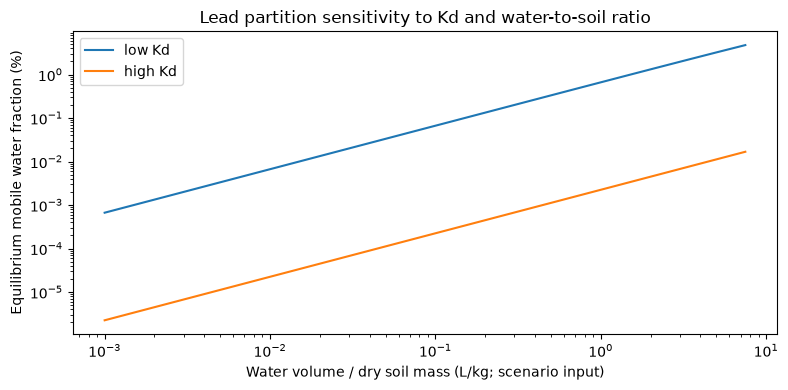

In [8]:
water_to_soil_plot = []
ratio = 0.001

while ratio <= 10.0:
    water_to_soil_plot.append(ratio)
    ratio *= 1.5

plt.figure(figsize=(8, 4))

for kd_name, kd_value in lead_kd_values.items():
    mobile_percentages = []

    for water_to_soil_ratio in water_to_soil_plot:
        mobile_fraction = water_to_soil_ratio / (water_to_soil_ratio + kd_value)
        mobile_percentages.append(mobile_fraction * 100)

    plt.plot(water_to_soil_plot, mobile_percentages, label=kd_name)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Water volume / dry soil mass (L/kg; scenario input)")
plt.ylabel("Equilibrium mobile water fraction (%)")
plt.title("Lead partition sensitivity to Kd and water-to-soil ratio")
plt.legend()
plt.tight_layout()
plt.show()

The curve rises as water volume increases relative to soil mass and as `Kd` decreases. The wide gap between EPA endpoints shows why a fixed mobile fraction is not defensible without a selected soil type, pH, dissolved-lead range, and water content.


## Nitrate-N: use flow and travel time

USGS SPARROW models represent in-stream nutrient loss with a first-order travel-time relationship. At reach scale, a candidate form is `delivered mass = incoming mass * exp(-k * travel_time)`, with `k` and travel time expressed in reciprocal, matching time units.

In [9]:
nitrate_k_times_travel = (0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0)
nitrate_delivery_rows = []

for dimensionless_exposure in nitrate_k_times_travel:
    delivered_fraction = math.exp(-dimensionless_exposure)
    removed_fraction = 1.0 - delivered_fraction
    row = {"dimensionless k × travel time": dimensionless_exposure, "fraction delivered": delivered_fraction, "fraction removed": removed_fraction}
    nitrate_delivery_rows.append(row)

nitrate_delivery_sensitivity = pd.DataFrame(nitrate_delivery_rows)
display(nitrate_delivery_sensitivity.round(4))

,dimensionless k × travel time,fraction delivered,fraction removed
0,0.00,1.0000,0.0000
1,0.10,0.9048,0.0952
2,0.25,0.7788,0.2212
3,0.50,0.6065,0.3935
4,1.00,0.3679,0.6321
5,2.00,0.1353,0.8647
6,5.00,0.0067,0.9933


This table checks the shape of the first-order equation only: delivery falls as the dimensionless product `k × travel_time` grows. Annual simulations still need catchment-specific flow, volume, and load inputs. Convert kg N/m³ to mg N/L by multiplying by 1,000.

### Nitrate-N pilot: Mississippi River at Keokuk

I used USGS site 05474500 as a pilot because it has paired nitrate-plus-nitrite sensor measurements and streamflow. The site is on the Mississippi River at Keokuk, Iowa, with a drainage area of about 119,000 square miles. It is a large, regulated river site, not a small or region-contained catchment.

The downloaded nitrate series contains USGS parameter 99133: in situ nitrate plus nitrite, reported in mg/L as nitrogen. A matching daily mean discharge series is available at the same site. This is a partial-year nitrate-plus-nitrite record, not a full annual nitrate-only series. The data files are in `../data/`.

The calculation averages available 15-minute concentrations for each day, multiplies that daily mean by the USGS daily mean discharge and 24 hours, then sums daily fluxes by month. The resulting flux is approximate because it multiplies daily mean concentration by daily mean flow. USGS load methods show that sampling frequency and high-flow coverage affect load accuracy.

Sources: [USGS Keokuk monitoring location](https://waterdata.usgs.gov/monitoring-location/USGS-05474500/), [USGS annual load methods review](https://pubs.usgs.gov/publication/sir20195084), [USGS nitrate-plus-nitrite code definition](https://water.code-pages.usgs.gov/dataRetrieval/articles/dataRetrieval.html).


In [ ]:
nitrate_file = "../data/usgs_05474500_nitrate_2023_2026.rdb"
discharge_file = "../data/usgs_05474500_discharge_daily_2023_2026.rdb"

nitrate_samples = pd.read_csv(nitrate_file, sep="\t", comment="#", dtype=str)
discharge_rows = pd.read_csv(discharge_file, sep="\t", comment="#", dtype=str)

In [ ]:
nitrate_samples = nitrate_samples[nitrate_samples["agency_cd"] == "USGS"].copy()
discharge_rows = discharge_rows[discharge_rows["agency_cd"] == "USGS"].copy()
nitrate_samples["datetime"] = pd.to_datetime(nitrate_samples["datetime"])
nitrate_samples["date"] = nitrate_samples["datetime"].dt.floor("D")
nitrate_samples["nitrate_plus_nitrite_mg_n_l"] = pd.to_numeric(nitrate_samples["328007_99133"], errors="coerce")
discharge_rows["date"] = pd.to_datetime(discharge_rows["datetime"])
discharge_rows["discharge_cfs"] = pd.to_numeric(discharge_rows["224327_00060_00003"], errors="coerce")

In [ ]:
nitrate_daily_rows = []
for date_value, daily_samples in nitrate_samples.groupby("date", sort=True):
    mean_concentration = daily_samples["nitrate_plus_nitrite_mg_n_l"].mean()
    sample_count = daily_samples["nitrate_plus_nitrite_mg_n_l"].count()
    nitrate_daily_rows.append({"date": date_value, "nitrate_plus_nitrite_mean_mg_n_l": mean_concentration, "15_minute_samples":sample_count})

nitrate_daily = pd.DataFrame(nitrate_daily_rows)
discharge_daily = discharge_rows[["date", "discharge_cfs"]].copy()
nitrate_daily = nitrate_daily.merge(discharge_daily, on="date", how="inner")

In [ ]:
cubic_feet_to_cubic_meters = 0.028316846592
seconds_per_day = 86400

nitrate_daily["discharge_m3_day"] = nitrate_daily["discharge_cfs"] * cubic_feet_to_cubic_meters * seconds_per_day
nitrate_daily["approximate_nitrate_plus_nitrite_load_kg_day"] = nitrate_daily["nitrate_plus_nitrite_mean_mg_n_l"] * nitrate_daily["discharge_m3_day"] / 1000
nitrate_daily["year_month"] = nitrate_daily["date"].dt.strftime("%Y-%m")

In [10]:
nitrate_month_rows = []
for year_month, month_days in nitrate_daily.groupby("year_month", sort=True):
    total_load_kg = month_days["approximate_nitrate_plus_nitrite_load_kg_day"].sum()
    total_flow_m3 = month_days["discharge_m3_day"].sum()
    flow_weighted_concentration = total_load_kg * 1000 / total_flow_m3
    calendar_days = month_days["date"].iloc[0].days_in_month
    days_with_data = month_days["date"].nunique()
    monthly_row = {
        "month": year_month,
        "days_with_paired_data": days_with_data,
        "calendar_days": calendar_days,
        "coverage_pct": 100 * days_with_data / calendar_days,
        "arithmetic_mean_concentration_mg_n_l": month_days["nitrate_plus_nitrite_mean_mg_n_l"].mean(),
        "flow_weighted_concentration_mg_n_l": flow_weighted_concentration,
        "mean_discharge_m3_s": month_days["discharge_cfs"].mean() * cubic_feet_to_cubic_meters,
        "approximate_load_kg_n": total_load_kg,
    }
    nitrate_month_rows.append(monthly_row)

nitrate_monthly = pd.DataFrame(nitrate_month_rows)
display(nitrate_monthly.round(2))

,month,days_with_paired_data,calendar_days,coverage_pct,arithmetic_mean_concentration_mg_n_l,flow_weighted_concentration_mg_n_l,mean_discharge_m3_s,approximate_load_kg_n
0,2023-04,18,30,60.00,2.79,2.76,5342.45,22957340.78
1,2023-05,31,31,100.00,2.88,2.77,5675.24,42118415.72
2,2023-06,30,30,100.00,2.36,2.60,1847.96,12468031.25
3,2023-07,31,31,100.00,0.81,0.84,1052.29,2380214.91
4,2023-08,23,31,74.19,0.17,0.15,914.76,267411.71
5,2023-09,30,30,100.00,0.52,0.53,681.87,943201.05
6,2023-10,31,31,100.00,0.88,0.90,1147.84,2770048.01
7,2023-11,23,30,76.67,1.17,1.16,1368.57,3163042.62


,USGS approved 15-minute measurements,days with paired nitrate and flow,mean samples per observed day,median samples per observed day,minimum samples in an observed day,partial-period approximate load_kg_n
0,20591,217,94.89,96.0,42,87067706.06


In [ ]:
nitrate_measurement_count = nitrate_samples["nitrate_plus_nitrite_mg_n_l"].count()
nitrate_day_count = len(nitrate_daily)
mean_samples_per_day = nitrate_daily["15_minute_samples"].mean()
median_samples_per_day = nitrate_daily["15_minute_samples"].median()
minimum_samples_per_day = nitrate_daily["15_minute_samples"].min()
partial_period_load_kg = nitrate_daily["approximate_nitrate_plus_nitrite_load_kg_day"].sum()

In [ ]:
nitrate_pilot_summary = pd.DataFrame([{"USGS approved 15-minute measurements": nitrate_measurement_count,
                                       "days with paired nitrate and flow": nitrate_day_count,
                                       "mean samples per observed day": mean_samples_per_day,
                                       "median samples per observed day": median_samples_per_day,
                                       "minimum samples in an observed day": minimum_samples_per_day,
                                       "partial-period approximate load_kg_n": partial_period_load_kg
                                       }])

display(nitrate_pilot_summary.round(2))

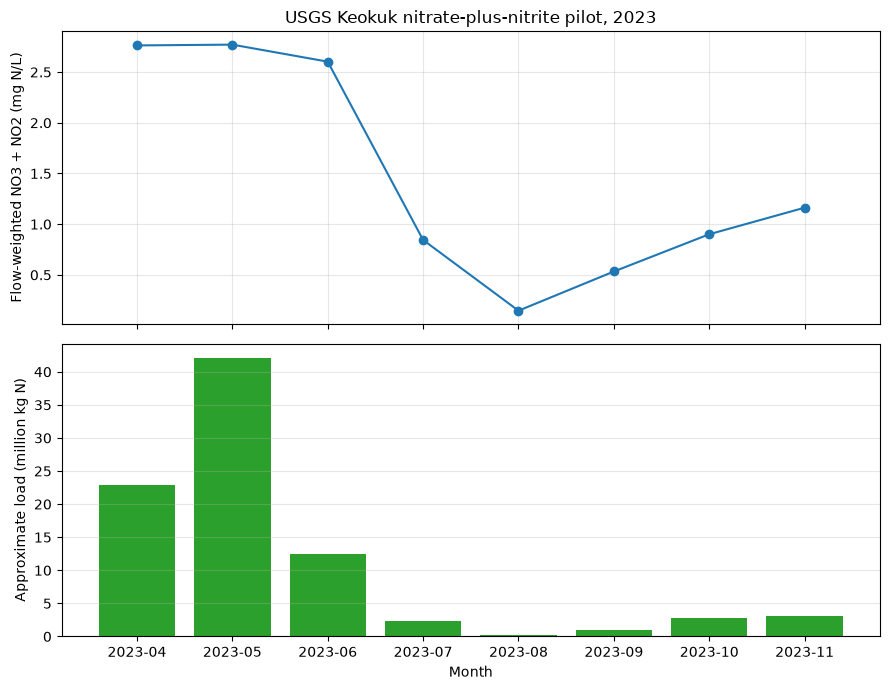

In [11]:
nitrate_month_numbers = list(range(len(nitrate_monthly)))

figure, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(nitrate_month_numbers, nitrate_monthly["flow_weighted_concentration_mg_n_l"], marker="o", color="tab:blue")
axes[0].set_ylabel("Flow-weighted NO3 + NO2 (mg N/L)")
axes[0].set_title("USGS Keokuk nitrate-plus-nitrite pilot, 2023")
axes[0].grid(alpha=0.3)

axes[1].bar(nitrate_month_numbers, nitrate_monthly["approximate_load_kg_n"] / 1000000, color="tab:green")
axes[1].set_ylabel("Approximate load (million kg N)")
axes[1].set_xlabel("Month")
axes[1].set_xticks(nitrate_month_numbers, nitrate_monthly["month"])
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


The paired record covers 217 days from April 13 to November 23, 2023. It has 20,591 approved 15-minute nitrate-plus-nitrite readings, with a median of 96 readings on each observed day. The flow-weighted monthly concentration ranges from 0.147 mg N/L in August to 2.771 mg N/L in May. The estimated load over the 217-day period is about 87.1 million kg N.

The large spring load reflects both elevated concentration and high discharge in this large river. This pilot supports the need for monthly water concentration and flow inputs. To calibrate reach removal, the next evidence step is to pair upstream and downstream loads or use site-specific reach measurements; an outlet time series alone cannot separate watershed inputs from in-stream removal.


## PM2.5: calculate a regional annual exposure baseline

The CDC National Environmental Public Health Tracking dataset provides daily county estimates of PM2.5. The `pm25_pop_pred` field is a population-weighted spatial estimate within each county, in micrograms per cubic meter. I average the daily values over 2020 for each county, then weight county means by the Census Bureau's 2020 county population estimates to summarize the four Census regions.

This establishes an empirical exposure baseline for 2020.  The county population file is the Census Bureau's 2020 population estimate from its 2023 vintage. The data and calculation are kept separate from Study 3's uncalibrated emissions model.

Sources: [CDC daily county PM2.5 dataset](https://data.cdc.gov/Environmental-Health-Toxicology/Daily-County-Level-PM2-5-Concentrations-2001-2022/53mz-4zqd) and [Census Bureau county population estimates](https://www2.census.gov/programs-surveys/popest/datasets/2020-2023/counties/totals/co-est2023-alldata.csv).


In [12]:
pm25_county_file = "../data/cdc_pm25_county_annual_2020.csv"
county_population_file = "../data/census_county_population_2020.csv"

pm25_counties = pd.read_csv(pm25_county_file, dtype={"statefips": str, "countyfips": str})
county_population = pd.read_csv(county_population_file, dtype={"county_fips": str})

,region,annual_PM2.5_exposure_2020_ug_m3,counties_with_estimates,population_coverage_pct
0,Northeast,7.42,208,93.76
1,Midwest,8.08,1044,99.83
2,South,8.15,1400,99.78
3,West,10.61,399,97.03


In [ ]:
pm25_counties["county_fips"] = pm25_counties["statefips"].str.zfill(2) + pm25_counties["countyfips"].str.zfill(3)
pm25_counties = pm25_counties.merge(county_population, on="county_fips", how="inner")

census_region_states = {
    "Northeast": ("Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont", "New Jersey", "New York", "Pennsylvania"),
    "Midwest": ("Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin", "Iowa", "Kansas", "Minnesota", "Missouri", "Nebraska", "North Dakota", "South Dakota"),
    "South": ("Delaware", "District of Columbia", "Florida", "Georgia", "Maryland", "North Carolina", "South Carolina", "Virginia", "West Virginia", "Alabama", "Kentucky", "Mississippi", "Tennessee", "Arkansas", "Louisiana", "Oklahoma", "Texas"),
    "West": ("Alaska", "Arizona", "California", "Colorado", "Hawaii", "Idaho", "Montana", "Nevada", "New Mexico", "Oregon", "Utah", "Washington", "Wyoming"),
}

state_to_region = {}
for region_name, state_names in census_region_states.items():
    for state_name in state_names:
        state_to_region[state_name] = region_name

pm25_counties["region"] = pm25_counties["STNAME"].map(state_to_region)
pm25_counties["population_weighted_pm25"] = pm25_counties["annual_pm25_pop_pred"] * pm25_counties["POPESTIMATE2020"]

In [ ]:
regional_pm25_rows = []
for region_name in census_region_states:
    region_counties = pm25_counties[pm25_counties["region"] == region_name]
    region_population = county_population[county_population["STNAME"].isin(census_region_states[region_name])]
    covered_population = region_counties["POPESTIMATE2020"].sum()
    total_population = region_population["POPESTIMATE2020"].sum()
    annual_exposure = region_counties["population_weighted_pm25"].sum() / covered_population
    population_coverage = 100 * covered_population / total_population

    regional_pm25_rows.append({
        "region": region_name,
        "annual_PM2.5_exposure_2020_ug_m3": annual_exposure,
        "counties_with_estimates": len(region_counties),
        "population_coverage_pct": population_coverage,
    })

regional_pm25 = pd.DataFrame(regional_pm25_rows)
display(regional_pm25.round(2))

The table provides a 2020 regional exposure baseline using population-weighted county estimates. The West is highest in this dataset, while the Northeast is lowest. Coverage is reported because some county estimates do not join to the population file.


## What changes if the model step is shorter?

The PM2.5 source contains daily county exposure estimates, so I also aggregate it to monthly values for 2020. The monthly mean is an average concentration over the days in that month. The annual mean is a day-weighted average of the monthly means.

The comparison helps decide whether annual observations are enough for the environment. Shorter steps can represent seasonal or episodic pollution, but annual budgets and flows need consistent conversions and the CO2 impulse response must be evaluated at the same time resolution.

### How to convert quantities between time scales

| Quantity | Physical unit | Daily/monthly/annual treatment |
|---|---|---|
| PM2.5 exposure | Concentration, ug/m^3 | Average daily concentrations to get a monthly mean. Average monthly means weighted by days to get an annual mean. Do not divide a concentration by 12 or 365. |
| CO2 input | Emissions, GtCO2 per year | If emissions are assumed uniform through the year, monthly input is annual input divided by 12. Apply each monthly pulse through the impulse-response function using its age in years (`age_months / 12`). |
| Nitrate-N | Concentration in mg N/L; flow in m^3/month | Monthly load in kg N is `concentration * monthly_flow / 1000`. Annual load is the sum of monthly loads. Use monthly flow and concentration when they are available. |
| Lead in soil | Concentration in mg Pb/kg dry soil; total stock in mg or kg | Convert concentration to total mass using dry-soil mass. Lead has no natural decay; monthly removal or immobilization must use a rate or a consistently converted fraction. |
| Annual proportional removal | Fraction removed per year | To preserve the same annual survival with a constant monthly process, use `f_month = 1 - (1 - f_year)^(1/12)`. Do not use `f_year / 12` when removal compounds over months. |
| Annual first-order rate | Rate constant per year | Convert to per month with `k_month = k_year / 12`; calculate loss as `1 - exp(-k_month * time_months)` with consistent units. |

In [13]:
monthly_pm25_file = "../data/cdc_pm25_county_monthly_2020.csv"
monthly_pm25_counties = pd.read_csv(monthly_pm25_file, dtype={"statefips": str, "countyfips": str})
monthly_pm25_counties["county_fips"] = monthly_pm25_counties["statefips"].str.zfill(2) + monthly_pm25_counties["countyfips"].str.zfill(3)
monthly_pm25_counties = monthly_pm25_counties.merge(county_population, on="county_fips", how="inner")
monthly_pm25_counties["region"] = monthly_pm25_counties["STNAME"].map(state_to_region)
monthly_pm25_counties["population_weighted_pm25"] = monthly_pm25_counties["monthly_pm25_pop_pred"] * monthly_pm25_counties["POPESTIMATE2020"]

region,Midwest,Northeast,South,West
month,,,,
Jan,8.89,7.88,7.35,9.08
Feb,8.18,8.51,6.88,8.58
Mar,7.93,6.43,8.15,5.24
Apr,7.77,5.99,7.98,5.81
May,5.87,5.63,6.84,6.51
Jun,8.17,7.25,9.50,6.36
Jul,8.80,8.77,9.75,8.30
Aug,7.81,7.94,8.29,13.21
Sep,7.39,6.55,8.11,27.41


,region,annual_mean_from_months_ug_m3,lowest_month,lowest_month_mean_ug_m3,highest_month,highest_month_mean_ug_m3,monthly_range_pct_of_annual
0,Northeast,7.42,May,5.63,Dec,9.17,47.78
1,Midwest,8.08,May,5.87,Dec,10.46,56.90
2,South,8.15,May,6.84,Jul,9.75,35.75
3,West,10.61,Mar,5.24,Sep,27.41,209.01


In [ ]:
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
month_day_counts = {1: 31, 2: 29, 3: 31, 4: 30, 5: 31, 6: 30, 7: 31, 8: 31, 9: 30, 10: 31, 11: 30, 12: 31}
monthly_region_rows = []

for region_name in census_region_states:
    for month_number, month_name in month_names.items():
        selected_counties = monthly_pm25_counties[(monthly_pm25_counties["region"] == region_name) & (monthly_pm25_counties["month"] == month_number)]
        covered_population = selected_counties["POPESTIMATE2020"].sum()
        monthly_exposure = selected_counties["population_weighted_pm25"].sum() / covered_population
        monthly_region_rows.append({
            "region": region_name,
            "month_number": month_number,
            "month": month_name,
            "annual_PM2.5_exposure_ug_m3": monthly_exposure,
            "counties_with_estimates": selected_counties["county_fips"].nunique(),
        })

monthly_region_exposure = pd.DataFrame(monthly_region_rows)
monthly_region_table = monthly_region_exposure.pivot(index="month", columns="region", values="annual_PM2.5_exposure_ug_m3")
monthly_region_table = monthly_region_table.reindex(list(month_names.values()))
display(monthly_region_table.round(2))

In [ ]:
monthly_summary_rows = []
for region_name in census_region_states:
    region_months = monthly_region_exposure[monthly_region_exposure["region"] == region_name]
    lowest_month = region_months.loc[region_months["annual_PM2.5_exposure_ug_m3"].idxmin()]
    highest_month = region_months.loc[region_months["annual_PM2.5_exposure_ug_m3"].idxmax()]
    annual_from_months = 0.0

    for _, month_row in region_months.iterrows():
        monthly_mean = month_row["annual_PM2.5_exposure_ug_m3"]
        month_number = month_row["month_number"]
        annual_from_months += monthly_mean * month_day_counts[month_number] / 366

    monthly_range = highest_month["annual_PM2.5_exposure_ug_m3"] - lowest_month["annual_PM2.5_exposure_ug_m3"]
    range_percent_of_annual = 100 * monthly_range / annual_from_months
    monthly_summary_rows.append({
        "region": region_name,
        "annual_mean_from_months_ug_m3": annual_from_months,
        "lowest_month": lowest_month["month"],
        "lowest_month_mean_ug_m3": lowest_month["annual_PM2.5_exposure_ug_m3"],
        "highest_month": highest_month["month"],
        "highest_month_mean_ug_m3": highest_month["annual_PM2.5_exposure_ug_m3"],
        "monthly_range_pct_of_annual": range_percent_of_annual,
    })

monthly_exposure_summary = pd.DataFrame(monthly_summary_rows)
display(monthly_exposure_summary.round(2))

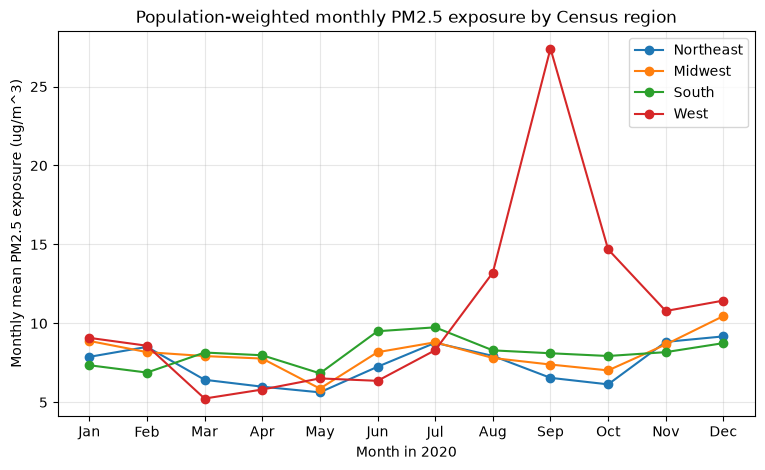

In [14]:
plt.figure(figsize=(9, 5))

for region_name in census_region_states:
    region_months = monthly_region_exposure[monthly_region_exposure["region"] == region_name]
    plt.plot(region_months["month_number"], region_months["annual_PM2.5_exposure_ug_m3"], marker="o", label=region_name)

plt.xticks(list(month_names.keys()), list(month_names.values()))
plt.ylabel("Monthly mean PM2.5 exposure (ug/m^3)")
plt.xlabel("Month in 2020")
plt.title("Population-weighted monthly PM2.5 exposure by Census region")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The table shows monthly concentration means, and the summary compares the highest and lowest month with the day-weighted annual mean. In this 2020 dataset, the West has a pronounced September peak: about 27.41 ug/m^3 compared with 5.24 ug/m^3 in March. Its annual mean is about 10.61 ug/m^3. Annual reporting therefore hides a large short-term exposure contrast. The other regions also vary by month, although less sharply in this year.

This supports preserving monthly PM2.5 exposure states if agents need to respond to short-lived pollution events.


## PM2.5: calibrate exposure separately from emissions

EPA's reduced-form Source-Receptor Matrix estimates annual concentration changes at receptor counties from emission changes in source counties. This is a better mathematical form than carrying an annual PM2.5 concentration as a persistent stock. The current four-region matrix in Notebook 03 is hypothetical.

To replace it, use a matching EPA matrix and emissions inventory, retain county source and receptor detail while calculating, then aggregate receptor concentrations to Census regions using a stated population weighting.